In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [2]:
# Portugal
admin = gpd.read_file("gadm41_PRT_0.json")
# Explode list elements into rows
gdf_pt = admin.explode(index_parts=False).reset_index(drop=True)
# Reproject
gdf_pt_proj = gdf_pt.to_crs("EPSG:3763")
# Largest poly
idx = gdf_pt_proj.geometry.area.idxmax()
# Pt boundary
gdf_mainland = gdf_pt.loc[[idx]].copy()

In [3]:
wind_turbines = gpd.read_file("ventodyne_turbines_in_view_2026-10-06T10-46-06Z.geojson")

In [4]:
# Reproject to meters
area = gdf_mainland.to_crs("EPSG:3763")
wind_turbines_3763 = wind_turbines.to_crs("EPSG:3763")
# Clip 
wind_turbines_clipped = gpd.clip(wind_turbines_3763, area)

In [5]:
# Reproject to meters
points = wind_turbines_clipped.to_crs("EPSG:3763")
mainland = gdf_mainland.to_crs("EPSG:3763")

# Grid origin
minx, miny, maxx, maxy = mainland.total_bounds
cell_size = 10000  

# Each point to a cell
points["col"] = np.floor((points.geometry.x - minx) / cell_size).astype(int)
points["row"] = np.floor((points.geometry.y - miny) / cell_size).astype(int)

# Count points in cells
counts = (
     points
    .groupby(["row", "col"])
    .size()
    .reset_index(name="count")
)

# Cell centres
counts["x"] = minx + (counts["col"] + 0.5) * cell_size
counts["y"] = miny + (counts["row"] + 0.5) * cell_size

# Convert to gdf
grid_points = gpd.GeoDataFrame(counts, geometry=gpd.points_from_xy(counts.x, counts.y), crs=points.crs)

# Stat
max_count = grid_points["count"].max()
total_num = len(grid_points)

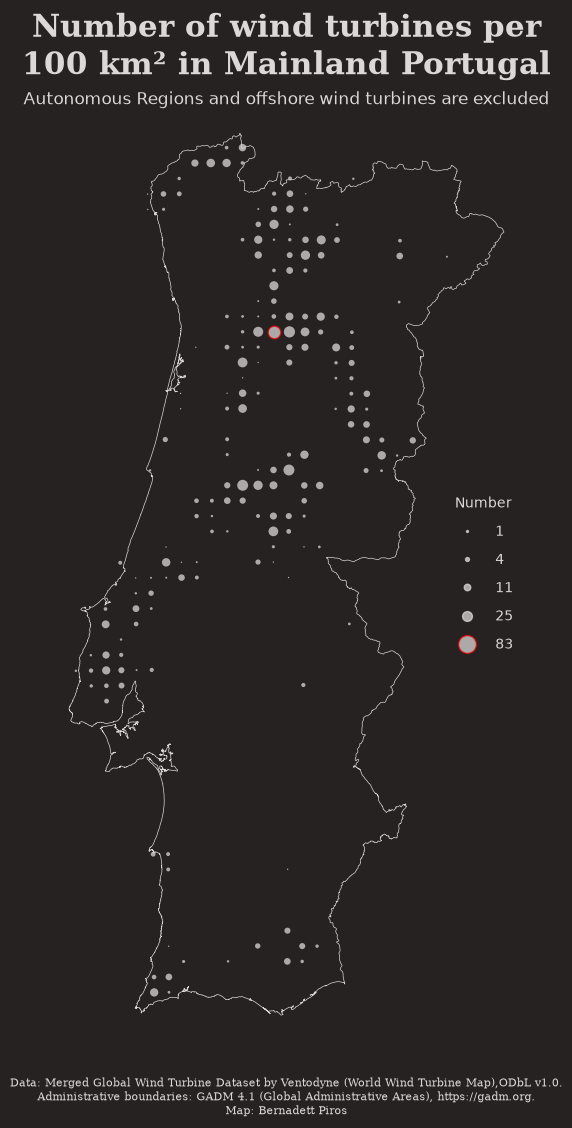

In [6]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#252221")

mainland_4326 = mainland.to_crs("EPSG:4326")
grid_points_4326 = grid_points.to_crs("EPSG:4326")

# Portugal boundary
mainland_4326.boundary.plot(ax=ax, color="#dbd8d7", lw=0.5)

# Wind turbines
for i, (index, row) in enumerate(grid_points.iterrows()):
    max_color = "#eb0002" if row["count"] == max_count else "none"

    ax.scatter(grid_points_4326.geometry.x.iloc[i], grid_points_4326.geometry.y.iloc[i],
               s=row["count"], color="#dbd8d7", ec=max_color, alpha=0.75)

# Legend 
legend_counts = [1, 4, 11, 25, max_count]

legend_elements = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#dbd8d7",
        markeredgecolor="#eb0002" if count == max_count else "#dbd8d7",
        markersize=(count * 2) ** 0.5, alpha=0.75, label=str(count)) for count in legend_counts]

legend = ax.legend(handles=legend_elements, title="Number", loc="center right",
                   labelcolor="#dbd8d7", frameon=False, labelspacing=1, handletextpad=1)

legend.get_title().set_color("#dbd8d7")

# Title
fig.text(0.5, 1,
         "Number of wind turbines per\n100 km² in Mainland Portugal",
         size=22, color="#dbd8d7", weight="bold", fontfamily="serif", ha="center")

# Subtitle
fig.text(0.5, 0.97,
         "Autonomous Regions and offshore wind turbines are excluded",
         size=12, color="#dbd8d7", ha="center")

# Caption
fig.text(0.5, -0.04,
        f"Data: Merged Global Wind Turbine Dataset by Ventodyne (World Wind Turbine Map),ODbL v1.0.\n"
        f"Administrative boundaries: GADM 4.1 (Global Administrative Areas), https://gadm.org.\n"
        f"Map: Bernadett Piros",
         size=8, color="#dbd8d7", fontfamily="DejaVu Serif", ha="center")
         
ax.axis("off")
plt.tight_layout()
plt.show()

# Save figure
#fig.savefig("wind_turbines.png", bbox_inches="tight", pad_inches=0.2)